In [ ]:
import pandas as pd
import numpy as np
import sklearn

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)

try:
    import catboost
    print("catboost:", catboost.__version__)
except ImportError:
    print("CatBoost not installed")

try:
    import lightgbm
    print("lightgbm:", lightgbm.__version__)
except ImportError:
    print("LightGBM not installed")

try:
    import xgboost
    print("xgboost:", xgboost.__version__)
except ImportError:
    print("XGBoost not installed")

pandas: 2.2.3
numpy: 2.1.3
sklearn: 1.6.1
CatBoost not installed
lightgbm: 4.6.0
xgboost: 3.4.1


In [ ]:
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submission = pd.read_csv("submission.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Submission shape:", submission.shape)

display(train.head())

Train shape: (18076, 12)
Test shape: (4520, 11)
Submission shape: (4520, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


In [ ]:
X = train.drop(columns=["price"])
y = train["price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (18076, 11)
y shape: (18076,)


In [ ]:
print(train.dtypes)

id                    int64
airline              object
flight               object
source_city          object
departure_time       object
stops                object
arrival_time         object
destination_city     object
flight_class         object
duration            float64
days_left             int64
price                 int64
dtype: object


In [ ]:
from sklearn.model_selection import KFold

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, valid_idx) in enumerate(kf.split(X), 1):
    print(
        f"Fold {fold}: "
        f"train={len(train_idx)}, "
        f"validation={len(valid_idx)}"
    )

Fold 1: train=14460, validation=3616
Fold 2: train=14461, validation=3615
Fold 3: train=14461, validation=3615
Fold 4: train=14461, validation=3615
Fold 5: train=14461, validation=3615


In [ ]:
# Basic data-quality checks
print("Missing values in train:")
print(train.isna().sum())

print("\nMissing values in test:")
print(test.isna().sum())

print("\nDuplicate training rows:", train.duplicated().sum())
print("Duplicate test rows:", test.duplicated().sum())
print("Duplicate train IDs:", train["id"].duplicated().sum())
print("Duplicate test IDs:", test["id"].duplicated().sum())
print("IDs shared by train and test:", len(set(train["id"]) & set(test["id"])))

# Target summary
print("\nPrice summary:")
display(train["price"].describe())

# Compare average price across ID ranges.
# This is a diagnostic only; it does not prove that ID has a meaningful cause.
id_summary = (
    train.assign(id_bin=pd.qcut(train["id"], q=10, duplicates="drop"))
         .groupby("id_bin", observed=True)
         .agg(
             rows=("price", "size"),
             mean_price=("price", "mean"),
             median_price=("price", "median"),
             min_id=("id", "min"),
             max_id=("id", "max"),
         )
         .reset_index()
)

print("\nPrice by ID range:")
display(id_summary)

Missing values in train:
id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
price               0
dtype: int64

Missing values in test:
id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
dtype: int64

Duplicate training rows: 0
Duplicate test rows: 0
Duplicate train IDs: 0
Duplicate test IDs: 0
IDs shared by train and test: 0

Price summary:


,price
count,18076.000000
mean,280.264550
std,221.965133
min,0.000000
25%,157.000000
50%,234.000000
75%,336.000000
max,8996.000000



Price by ID range:


,id_bin,rows,mean_price,median_price,min_id,max_id
0,"(-0.001, 2219.5]",1808,363.771571,307.0,0,2219
1,"(2219.5, 4537.0]",1808,358.079093,302.0,2220,4537
2,"(4537.0, 6815.5]",1807,326.379081,274.0,4538,6815
3,"(6815.5, 9090.0]",1808,301.643805,253.0,6816,9090
4,"(9090.0, 11329.5]",1807,281.131710,234.0,9091,11329
5,"(11329.5, 13554.0]",1808,258.761062,219.0,11330,13554
6,"(13554.0, 15825.5]",1807,240.152739,199.0,13555,15825
7,"(15825.5, 18107.0]",1808,242.085730,184.0,15826,18107
8,"(18107.0, 20343.0]",1807,212.970670,169.0,18108,20342
9,"(20343.0, 22595.0]",1808,217.636615,176.0,20344,22595


In [ ]:
# Compare how train and test IDs are distributed across the full ID range
all_ids = pd.concat([train["id"], test["id"]], ignore_index=True)
id_bins = pd.cut(all_ids, bins=10)

train_id_counts = (
    pd.cut(train["id"], bins=id_bins.cat.categories)
      .value_counts(sort=False)
      .rename("train_rows")
)

test_id_counts = (
    pd.cut(test["id"], bins=id_bins.cat.categories)
      .value_counts(sort=False)
      .rename("test_rows")
)

id_distribution = pd.concat([train_id_counts, test_id_counts], axis=1)
id_distribution["train_share"] = (
    id_distribution["train_rows"] / len(train)
)
id_distribution["test_share"] = (
    id_distribution["test_rows"] / len(test)
)

print("Train and test counts across ID ranges:")
display(id_distribution)

print("\nLowest-priced training rows:")
display(train.nsmallest(10, "price"))

print("\nHighest-priced training rows:")
display(train.nlargest(10, "price"))

Train and test counts across ID ranges:


,train_rows,test_rows,train_share,test_share
id,,,,
"(-22.595, 2259.5]",1835,425,0.101516,0.094027
"(2259.5, 4519.0]",1766,494,0.097699,0.109292
"(4519.0, 6778.5]",1790,469,0.099026,0.103761
"(6778.5, 9038.0]",1798,462,0.099469,0.102212
"(9038.0, 11297.5]",1828,431,0.101129,0.095354
"(11297.5, 13557.0]",1831,429,0.101295,0.094912
"(13557.0, 15816.5]",1799,460,0.099524,0.101770
"(15816.5, 18076.0]",1792,468,0.099137,0.103540
"(18076.0, 20335.5]",1824,435,0.100907,0.096239



Lowest-priced training rows:


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
346,7703,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,13,0
934,12440,Southwest,WN 3903,Sacramento,Afternoon,one,Evening,San Jose,Economy,3.17,25,0
1352,13813,Southwest,WN 3797,San Jose,Morning,one,Afternoon,Sacramento,Economy,3.25,21,0
2762,4900,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,10,0
3101,5689,Southwest,WN 3687,Sacramento,Evening,one,Night,San Jose,Economy,3.08,9,0
4350,3307,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,6,0
5386,7879,Southwest,WN 3684,Sacramento,Morning,one,Afternoon,San Jose,Economy,3.08,15,0
5600,9839,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,16,0
5991,17620,Alaska_Airlines,AS 490,Sacramento,Early_Morning,one,Morning,San Jose,Economy,4.33,35,0
6642,4923,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,10,0



Highest-priced training rows:


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
15787,16,United,UA 729,Los Angeles,Late_Night,one,Morning,San Diego,Business,9.37,1,8996
15200,22275,Alaska_Airlines,AS 2224,San Diego,Night,one,Afternoon,San Jose,Business,14.52,43,5564
5936,19925,Alaska_Airlines,AS 668,Los Angeles,Early_Morning,one,Afternoon,San Jose,Business,5.58,37,3607
2473,13008,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,23,3204
12601,11469,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,19,3204
4249,7975,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,14,3194
10611,5522,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.28,10,3194
12674,5650,United,UA 1023,Sacramento,Morning,one,Evening,San Jose,Business,6.70,10,3194
7528,4233,United,UA 1100,San Diego,Night,one,Morning,San Jose,Business,13.27,9,3029
12109,19085,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.43,37,2424


In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
from lightgbm import LGBMRegressor
import numpy as np
import pandas as pd

# Mark text columns as categories for LightGBM.
# The shared category lists keep each fold's feature representation consistent.
categorical_columns = X.select_dtypes(include="object").columns.tolist()
X_model = X.copy()

for column in categorical_columns:
    categories = X_model[column].dropna().unique()
    X_model[column] = pd.Categorical(X_model[column], categories=categories)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = {}

for use_id in [True, False]:
    columns = X_model.columns.tolist()
    if not use_id:
        columns.remove("id")

    fold_mae = []
    fold_rmse = []

    for fold, (train_idx, valid_idx) in enumerate(kf.split(X_model), start=1):
        X_train_fold = X_model.iloc[train_idx][columns]
        X_valid_fold = X_model.iloc[valid_idx][columns]
        y_train_fold = y.iloc[train_idx]
        y_valid_fold = y.iloc[valid_idx]

        model = LGBMRegressor(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1,
        )

        model.fit(
            X_train_fold,
            y_train_fold,
            categorical_feature=categorical_columns,
        )

        predictions = model.predict(X_valid_fold)

        fold_mae.append(mean_absolute_error(y_valid_fold, predictions))
        fold_rmse.append(np.sqrt(mean_squared_error(y_valid_fold, predictions)))

    results["with id" if use_id else "without id"] = {
        "fold_mae": fold_mae,
        "mean_mae": np.mean(fold_mae),
        "mean_rmse": np.mean(fold_rmse),
    }

for label, scores in results.items():
    print(f"\n{label}")
    print("MAE by fold:", [round(score, 2) for score in scores["fold_mae"]])
    print("Mean MAE:", round(scores["mean_mae"], 2))
    print("Mean RMSE:", round(scores["mean_rmse"], 2))


with id
MAE by fold: [54.01, 50.21, 50.99, 51.35, 52.11]
Mean MAE: 51.73
Mean RMSE: 127.15

without id
MAE by fold: [52.58, 50.48, 50.15, 52.5, 51.32]
Mean MAE: 51.4
Mean RMSE: 126.32


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import numpy as np

# Exclude id for this comparison, based on the first LightGBM results.
X_xgb = X.drop(columns=["id"])
categorical_columns = X_xgb.select_dtypes(include="object").columns.tolist()
numeric_columns = X_xgb.select_dtypes(exclude="object").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", min_frequency=2),
            categorical_columns,
        ),
        ("numeric", "passthrough", numeric_columns),
    ]
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_mae = []
fold_rmse = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X_xgb), start=1):
    model = make_pipeline(
        preprocessor,
        XGBRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=8,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1,
        ),
    )

    model.fit(X_xgb.iloc[train_idx], y.iloc[train_idx])
    predictions = model.predict(X_xgb.iloc[valid_idx])

    fold_mae.append(
        mean_absolute_error(y.iloc[valid_idx], predictions)
    )
    fold_rmse.append(
        np.sqrt(mean_squared_error(y.iloc[valid_idx], predictions))
    )

print("MAE by fold:", [round(score, 2) for score in fold_mae])
print("Mean MAE:", round(np.mean(fold_mae), 2))
print("Mean RMSE:", round(np.mean(fold_rmse), 2))

MAE by fold: [49.8, 47.36, 47.54, 46.9, 48.45]
Mean MAE: 48.01
Mean RMSE: 126.75


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import numpy as np

X_xgb = X.drop(columns=["id"])
categorical_columns = X_xgb.select_dtypes(include="object").columns.tolist()
numeric_columns = X_xgb.select_dtypes(exclude="object").columns.tolist()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_mae_log = []
fold_rmse_log = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X_xgb), start=1):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", min_frequency=2),
                categorical_columns,
            ),
            ("numeric", "passthrough", numeric_columns),
        ]
    )

    model = make_pipeline(
        preprocessor,
        XGBRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=8,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1,
        ),
    )

    # log1p allows zero prices; expm1 converts predictions back afterward.
    y_train_log = np.log1p(y.iloc[train_idx])
    model.fit(X_xgb.iloc[train_idx], y_train_log)

    predictions_log = model.predict(X_xgb.iloc[valid_idx])
    predictions = np.maximum(0, np.expm1(predictions_log))

    fold_mae_log.append(
        mean_absolute_error(y.iloc[valid_idx], predictions)
    )
    fold_rmse_log.append(
        np.sqrt(mean_squared_error(y.iloc[valid_idx], predictions))
    )

print("Log-target MAE by fold:", [round(score, 2) for score in fold_mae_log])
print("Log-target mean MAE:", round(np.mean(fold_mae_log), 2))
print("Log-target mean RMSE:", round(np.mean(fold_rmse_log), 2))

Log-target MAE by fold: [46.79, 43.98, 44.13, 43.61, 45.27]
Log-target mean MAE: 44.76
Log-target mean RMSE: 121.04


In [ ]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Keep the same feature choice as the XGBoost comparison: omit id.
X_lgb = X.drop(columns=["id"]).copy()
categorical_columns = X_lgb.select_dtypes(include="object").columns.tolist()

# Give each category column a consistent category list across folds.
for column in categorical_columns:
    categories = X_lgb[column].dropna().unique()
    X_lgb[column] = pd.Categorical(X_lgb[column], categories=categories)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_mae_log_lgb = []
fold_rmse_log_lgb = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X_lgb), start=1):
    model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1,
    )

    y_train_log = np.log1p(y.iloc[train_idx])

    model.fit(
        X_lgb.iloc[train_idx],
        y_train_log,
        categorical_feature=categorical_columns,
    )

    predictions_log = model.predict(X_lgb.iloc[valid_idx])
    predictions = np.maximum(0, np.expm1(predictions_log))

    fold_mae_log_lgb.append(
        mean_absolute_error(y.iloc[valid_idx], predictions)
    )
    fold_rmse_log_lgb.append(
        np.sqrt(mean_squared_error(y.iloc[valid_idx], predictions))
    )

print("LightGBM log-target MAE by fold:",
      [round(score, 2) for score in fold_mae_log_lgb])
print("LightGBM log-target mean MAE:",
      round(np.mean(fold_mae_log_lgb), 2))
print("LightGBM log-target mean RMSE:",
      round(np.mean(fold_rmse_log_lgb), 2))

LightGBM log-target MAE by fold: [48.36, 45.32, 45.08, 44.93, 47.03]
LightGBM log-target mean MAE: 46.14
LightGBM log-target mean RMSE: 121.71


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

X_xgb = X.drop(columns=["id"])
categorical_columns = X_xgb.select_dtypes(include="object").columns.tolist()
numeric_columns = X_xgb.select_dtypes(exclude="object").columns.tolist()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_predictions = np.zeros(len(X_xgb))

for fold, (train_idx, valid_idx) in enumerate(kf.split(X_xgb), start=1):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", min_frequency=2),
                categorical_columns,
            ),
            ("numeric", "passthrough", numeric_columns),
        ]
    )

    model = make_pipeline(
        preprocessor,
        XGBRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=8,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1,
        ),
    )

    y_train_log = np.log1p(y.iloc[train_idx])
    model.fit(X_xgb.iloc[train_idx], y_train_log)

    predictions_log = model.predict(X_xgb.iloc[valid_idx])
    oof_predictions[valid_idx] = np.maximum(0, np.expm1(predictions_log))

# Summarize error by actual price range
oof = pd.DataFrame({
    "actual_price": y,
    "predicted_price": oof_predictions,
})
oof["absolute_error"] = (
    oof["actual_price"] - oof["predicted_price"]
).abs()

oof["price_range"] = pd.cut(
    oof["actual_price"],
    bins=[-1, 100, 250, 500, 1000, float("inf")],
    labels=["0–100", "101–250", "251–500", "501–1000", "over 1000"],
)

print("Overall OOF MAE:",
      round(oof["absolute_error"].mean(), 2))

print("\nError by actual-price range:")
display(
    oof.groupby("price_range", observed=False)
       .agg(
           rows=("actual_price", "size"),
           mean_actual=("actual_price", "mean"),
           mean_predicted=("predicted_price", "mean"),
           mean_absolute_error=("absolute_error", "mean"),
       )
       .round(2)
)

print("\nLargest validation errors:")
display(
    oof.nlargest(10, "absolute_error")[
        ["actual_price", "predicted_price", "absolute_error"]
    ]
)

Overall OOF MAE: 44.76

Error by actual-price range:


,rows,mean_actual,mean_predicted,mean_absolute_error
price_range,,,,
0–100,2178,73.42,88.19,16.65
101–250,7631,181.93,190.00,24.45
251–500,6387,331.42,325.05,40.85
501–1000,1689,661.22,564.16,129.98
over 1000,191,1488.36,1053.34,553.17



Largest validation errors:


,actual_price,predicted_price,absolute_error
15787,8996,977.823730,8018.176270
15200,5564,448.069733,5115.930267
5936,3607,503.392792,3103.607208
7528,3029,850.594849,2178.405151
5972,2025,234.218536,1790.781464
3740,2025,275.877899,1749.122101
1573,2025,285.277588,1739.722412
16942,2025,331.993866,1693.006134
12674,3194,1539.851929,1654.148071
16444,2025,370.870880,1654.129120


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

X_compare = X.drop(columns=["id"])
categorical_columns = X_compare.select_dtypes(include="object").columns.tolist()
numeric_columns = X_compare.select_dtypes(exclude="object").columns.tolist()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_raw = np.zeros(len(X_compare))
oof_log = np.zeros(len(X_compare))

for train_idx, valid_idx in kf.split(X_compare):
    for target_type, predictions_array in [
        ("raw", oof_raw),
        ("log", oof_log),
    ]:
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(handle_unknown="ignore", min_frequency=2),
                    categorical_columns,
                ),
                ("numeric", "passthrough", numeric_columns),
            ]
        )

        model = make_pipeline(
            preprocessor,
            XGBRegressor(
                n_estimators=600,
                learning_rate=0.05,
                max_depth=8,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                tree_method="hist",
                random_state=42,
                n_jobs=-1,
            ),
        )

        y_fold = y.iloc[train_idx]
        if target_type == "log":
            y_fold = np.log1p(y_fold)

        model.fit(X_compare.iloc[train_idx], y_fold)
        fold_predictions = model.predict(X_compare.iloc[valid_idx])

        if target_type == "log":
            fold_predictions = np.maximum(0, np.expm1(fold_predictions))

        predictions_array[valid_idx] = fold_predictions

# Compare each version overall and across the same price ranges
price_bins = [-1, 100, 250, 500, 1000, float("inf")]
price_labels = ["0–100", "101–250", "251–500", "501–1000", "over 1000"]

comparison = pd.DataFrame({
    "actual": y.to_numpy(),
    "raw_prediction": oof_raw,
    "log_prediction": oof_log,
})
comparison["price_range"] = pd.cut(
    comparison["actual"],
    bins=price_bins,
    labels=price_labels,
)

for name, column in [
    ("Raw target", "raw_prediction"),
    ("Log target", "log_prediction"),
]:
    errors = comparison["actual"] - comparison[column]
    print(
        f"{name}: "
        f"MAE={mean_absolute_error(comparison['actual'], comparison[column]):.2f}, "
        f"RMSE={np.sqrt(mean_squared_error(comparison['actual'], comparison[column])):.2f}"
    )

print("\nAverage prediction minus actual by price range:")
display(
    comparison.groupby("price_range", observed=False)
    .apply(
        lambda group: pd.Series({
            "rows": len(group),
            "raw_bias": (group["raw_prediction"] - group["actual"]).mean(),
            "log_bias": (group["log_prediction"] - group["actual"]).mean(),
            "raw_MAE": (group["raw_prediction"] - group["actual"]).abs().mean(),
            "log_MAE": (group["log_prediction"] - group["actual"]).abs().mean(),
        }),
        include_groups=False,
    )
    .round(2)
)

Raw target: MAE=48.01, RMSE=129.57
Log target: MAE=44.76, RMSE=124.42

Average prediction minus actual by price range:


,rows,raw_bias,log_bias,raw_MAE,log_MAE
price_range,,,,,
0–100,2178.0,23.25,14.77,25.11,16.65
101–250,7631.0,15.52,8.07,29.85,24.45
251–500,6387.0,4.57,-6.37,43.34,40.85
501–1000,1689.0,-79.28,-97.06,119.06,129.98
over 1000,191.0,-359.36,-435.01,562.81,553.17


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

actual = y.to_numpy()
weights = []

for raw_weight in np.arange(0, 1.01, 0.1):
    # raw_weight is the share from the raw-target model;
    # the remaining share comes from the log-target model.
    blended = raw_weight * oof_raw + (1 - raw_weight) * oof_log

    weights.append({
        "raw_model_share": round(raw_weight, 1),
        "log_model_share": round(1 - raw_weight, 1),
        "MAE": mean_absolute_error(actual, blended),
        "RMSE": np.sqrt(mean_squared_error(actual, blended)),
    })

blend_results = pd.DataFrame(weights).round(2)
display(blend_results)

,raw_model_share,log_model_share,MAE,RMSE
0,0.0,1.0,44.76,124.42
1,0.1,0.9,44.79,124.21
2,0.2,0.8,44.91,124.15
3,0.3,0.7,45.10,124.27
4,0.4,0.6,45.36,124.55
5,0.5,0.5,45.66,124.99
6,0.6,0.4,46.03,125.59
7,0.7,0.3,46.44,126.35
8,0.8,0.2,46.91,127.28
9,0.9,0.1,47.43,128.35


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_ridge = X.drop(columns=["id"])
categorical_columns = X_ridge.select_dtypes(include="object").columns.tolist()
numeric_columns = X_ridge.select_dtypes(exclude="object").columns.tolist()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_oof = np.zeros(len(X_ridge))

for train_idx, valid_idx in kf.split(X_ridge):
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", min_frequency=2),
                categorical_columns,
            ),
            ("numeric", StandardScaler(), numeric_columns),
        ]
    )

    model = make_pipeline(
        preprocessor,
        Ridge(alpha=10.0),
    )

    model.fit(
        X_ridge.iloc[train_idx],
        np.log1p(y.iloc[train_idx]),
    )

    predictions_log = model.predict(X_ridge.iloc[valid_idx])
    ridge_oof[valid_idx] = np.maximum(0, np.expm1(predictions_log))

print("Ridge log-target MAE:",
      round(mean_absolute_error(y, ridge_oof), 2))
print("Ridge log-target RMSE:",
      round(np.sqrt(mean_squared_error(y, ridge_oof)), 2))

Ridge log-target MAE: 71.37
Ridge log-target RMSE: 147.55


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

# Start from the same features as the log-target XGBoost model.
X_base = X.drop(columns=["id"]).copy()

# Add two candidate features:
# 1. A directional route such as "San Jose -> Sacramento"
# 2. The numeric portion of a flight code such as "WN 3596" -> 3596
X_engineered = X_base.copy()
X_engineered["route"] = (
    X_engineered["source_city"] + " -> " + X_engineered["destination_city"]
)
X_engineered["flight_number"] = pd.to_numeric(
    X_engineered["flight"].str.extract(r"(\d+)")[0],
    errors="coerce",
)

print("Missing flight_number values:",
      X_engineered["flight_number"].isna().sum())

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def get_log_xgb_oof(features):
    categorical_columns = features.select_dtypes(include="object").columns.tolist()
    numeric_columns = features.select_dtypes(exclude="object").columns.tolist()
    predictions_oof = np.zeros(len(features))

    for train_idx, valid_idx in kf.split(features):
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(handle_unknown="ignore", min_frequency=2),
                    categorical_columns,
                ),
                ("numeric", "passthrough", numeric_columns),
            ]
        )

        model = make_pipeline(
            preprocessor,
            XGBRegressor(
                n_estimators=600,
                learning_rate=0.05,
                max_depth=8,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                tree_method="hist",
                random_state=42,
                n_jobs=-1,
            ),
        )

        model.fit(features.iloc[train_idx], np.log1p(y.iloc[train_idx]))
        predictions_log = model.predict(features.iloc[valid_idx])
        predictions_oof[valid_idx] = np.maximum(0, np.expm1(predictions_log))

    return predictions_oof

baseline_oof = get_log_xgb_oof(X_base)
engineered_oof = get_log_xgb_oof(X_engineered)

for name, predictions in [
    ("Original features", baseline_oof),
    ("Route + flight number", engineered_oof),
]:
    mae = mean_absolute_error(y, predictions)
    rmse = np.sqrt(mean_squared_error(y, predictions))
    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}")

Missing flight_number values: 0
Original features: MAE=44.76, RMSE=124.42
Route + flight number: MAE=43.66, RMSE=123.54


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import numpy as np

X_base = X.drop(columns=["id"]).copy()

X_route = X_base.copy()
X_route["route"] = (
    X_route["source_city"] + " -> " + X_route["destination_city"]
)

X_flight_number = X_base.copy()
X_flight_number["flight_number"] = pd.to_numeric(
    X_flight_number["flight"].str.extract(r"(\d+)")[0],
    errors="coerce",
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def score_log_xgb(features):
    categorical_columns = features.select_dtypes(include="object").columns.tolist()
    numeric_columns = features.select_dtypes(exclude="object").columns.tolist()
    predictions_oof = np.zeros(len(features))

    for train_idx, valid_idx in kf.split(features):
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(handle_unknown="ignore", min_frequency=2),
                    categorical_columns,
                ),
                ("numeric", "passthrough", numeric_columns),
            ]
        )

        model = make_pipeline(
            preprocessor,
            XGBRegressor(
                n_estimators=600,
                learning_rate=0.05,
                max_depth=8,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                tree_method="hist",
                random_state=42,
                n_jobs=-1,
            ),
        )

        model.fit(features.iloc[train_idx], np.log1p(y.iloc[train_idx]))
        predictions_log = model.predict(features.iloc[valid_idx])
        predictions_oof[valid_idx] = np.maximum(0, np.expm1(predictions_log))

    return predictions_oof

for name, features in [
    ("Route only", X_route),
    ("Flight number only", X_flight_number),
]:
    predictions = score_log_xgb(features)
    mae = mean_absolute_error(y, predictions)
    rmse = np.sqrt(mean_squared_error(y, predictions))
    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}")

Route only: MAE=43.83, RMSE=124.09
Flight number only: MAE=44.51, RMSE=123.85


In [ ]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

X_lgb_engineered = X.drop(columns=["id"]).copy()
X_lgb_engineered["route"] = (
    X_lgb_engineered["source_city"]
    + " -> "
    + X_lgb_engineered["destination_city"]
)
X_lgb_engineered["flight_number"] = pd.to_numeric(
    X_lgb_engineered["flight"].str.extract(r"(\d+)")[0],
    errors="coerce",
)

categorical_columns = (
    X_lgb_engineered.select_dtypes(include="object").columns.tolist()
)

for column in categorical_columns:
    categories = X_lgb_engineered[column].dropna().unique()
    X_lgb_engineered[column] = pd.Categorical(
        X_lgb_engineered[column],
        categories=categories,
    )

kf = KFold(n_splits=5, shuffle=True, random_state=42)
lgb_engineered_oof = np.zeros(len(X_lgb_engineered))

for train_idx, valid_idx in kf.split(X_lgb_engineered):
    model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1,
    )

    model.fit(
        X_lgb_engineered.iloc[train_idx],
        np.log1p(y.iloc[train_idx]),
        categorical_feature=categorical_columns,
    )

    predictions_log = model.predict(X_lgb_engineered.iloc[valid_idx])
    lgb_engineered_oof[valid_idx] = np.maximum(
        0, np.expm1(predictions_log)
    )

print("Engineered LightGBM MAE:",
      round(mean_absolute_error(y, lgb_engineered_oof), 2))
print("Engineered LightGBM RMSE:",
      round(np.sqrt(mean_squared_error(y, lgb_engineered_oof)), 2))

Engineered LightGBM MAE: 44.02
Engineered LightGBM RMSE: 124.46


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

actual = y.to_numpy()
blend_results = []

for xgb_weight in np.arange(0, 1.01, 0.1):
    blended = (
        xgb_weight * engineered_oof
        + (1 - xgb_weight) * lgb_engineered_oof
    )

    blend_results.append({
        "xgboost_share": round(xgb_weight, 1),
        "lightgbm_share": round(1 - xgb_weight, 1),
        "MAE": mean_absolute_error(actual, blended),
        "RMSE": np.sqrt(mean_squared_error(actual, blended)),
    })

display(pd.DataFrame(blend_results).round(2))


,xgboost_share,lightgbm_share,MAE,RMSE
0,0.0,1.0,44.02,124.46
1,0.1,0.9,43.53,123.84
2,0.2,0.8,43.15,123.34
3,0.3,0.7,42.86,122.95
4,0.4,0.6,42.68,122.68
5,0.5,0.5,42.59,122.53
6,0.6,0.4,42.61,122.49
7,0.7,0.3,42.73,122.58
8,0.8,0.2,42.95,122.78
9,0.9,0.1,43.25,123.10


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import numpy as np
import pandas as pd

# Recreate the engineered features used in the comparison.
X_check = X.drop(columns=["id"]).copy()
X_check["route"] = (
    X_check["source_city"] + " -> " + X_check["destination_city"]
)
X_check["flight_number"] = pd.to_numeric(
    X_check["flight"].str.extract(r"(\d+)")[0],
    errors="coerce",
)

categorical_columns = X_check.select_dtypes(include="object").columns.tolist()
numeric_columns = X_check.select_dtypes(exclude="object").columns.tolist()

# Use a different fold assignment from the earlier comparisons.
kf_check = KFold(n_splits=5, shuffle=True, random_state=2026)
xgb_oof_check = np.zeros(len(X_check))
lgb_oof_check = np.zeros(len(X_check))

# Make LightGBM's category definitions consistent across the folds.
X_lgb_check = X_check.copy()
for column in categorical_columns:
    categories = X_lgb_check[column].dropna().unique()
    X_lgb_check[column] = pd.Categorical(
        X_lgb_check[column],
        categories=categories,
    )

for train_idx, valid_idx in kf_check.split(X_check):
    # XGBoost
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", min_frequency=2),
                categorical_columns,
            ),
            ("numeric", "passthrough", numeric_columns),
        ]
    )
    xgb_model = make_pipeline(
        preprocessor,
        XGBRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=8,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1,
        ),
    )
    xgb_model.fit(X_check.iloc[train_idx], np.log1p(y.iloc[train_idx]))
    xgb_oof_check[valid_idx] = np.maximum(
        0,
        np.expm1(xgb_model.predict(X_check.iloc[valid_idx])),
    )

    # LightGBM
    lgb_model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1,
    )
    lgb_model.fit(
        X_lgb_check.iloc[train_idx],
        np.log1p(y.iloc[train_idx]),
        categorical_feature=categorical_columns,
    )
    lgb_oof_check[valid_idx] = np.maximum(
        0,
        np.expm1(lgb_model.predict(X_lgb_check.iloc[valid_idx])),
    )

blend_oof_check = 0.5 * xgb_oof_check + 0.5 * lgb_oof_check

for name, predictions in [
    ("XGBoost", xgb_oof_check),
    ("LightGBM", lgb_oof_check),
    ("50/50 blend", blend_oof_check),
]:
    mae = mean_absolute_error(y, predictions)
    rmse = np.sqrt(mean_squared_error(y, predictions))
    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}")

XGBoost: MAE=43.83, RMSE=125.68
LightGBM: MAE=44.25, RMSE=124.38
50/50 blend: MAE=42.69, RMSE=122.88


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import numpy as np
import pandas as pd

# Create the same engineered features for train and test.
def make_features(data):
    features = data.drop(columns=["id", "price"], errors="ignore").copy()
    features["route"] = (
        features["source_city"] + " -> " + features["destination_city"]
    )
    features["flight_number"] = pd.to_numeric(
        features["flight"].str.extract(r"(\d+)")[0],
        errors="coerce",
    )
    return features

X_full = make_features(train)
X_test = make_features(test)
y_full = train["price"]

categorical_columns = X_full.select_dtypes(include="object").columns.tolist()
numeric_columns = X_full.select_dtypes(exclude="object").columns.tolist()

# Train XGBoost on log prices.
xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", min_frequency=2),
            categorical_columns,
        ),
        ("numeric", "passthrough", numeric_columns),
    ]
)

xgb_model = make_pipeline(
    xgb_preprocessor,
    XGBRegressor(
        n_estimators=600,
        learning_rate=0.05,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
    ),
)

xgb_model.fit(X_full, np.log1p(y_full))
xgb_predictions = np.maximum(
    0,
    np.expm1(xgb_model.predict(X_test)),
)

# Train LightGBM on log prices.
X_lgb_full = X_full.copy()
X_lgb_test = X_test.copy()

# Use matching category definitions for train and test.
for column in categorical_columns:
    categories = pd.Index(
        pd.concat(
            [X_lgb_full[column], X_lgb_test[column]],
            ignore_index=True,
        ).dropna().unique()
    )
    X_lgb_full[column] = pd.Categorical(
        X_lgb_full[column], categories=categories
    )
    X_lgb_test[column] = pd.Categorical(
        X_lgb_test[column], categories=categories
    )

lgb_model = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1,
)

lgb_model.fit(
    X_lgb_full,
    np.log1p(y_full),
    categorical_feature=categorical_columns,
)
lgb_predictions = np.maximum(
    0,
    np.expm1(lgb_model.predict(X_lgb_test)),
)

# Average the two models' predictions.
blended_predictions = 0.5 * xgb_predictions + 0.5 * lgb_predictions

# Put predictions into the template by ID, preserving its row order.
prediction_by_id = pd.Series(
    blended_predictions,
    index=test["id"],
)
candidate_submission = submission.copy()
candidate_submission["price"] = candidate_submission["id"].map(prediction_by_id)

if candidate_submission["price"].isna().any():
    raise ValueError("Some submission IDs did not match the test data.")

candidate_submission.to_csv("submission_blended.csv", index=False)

print("Saved submission_blended.csv")
print("Rows:", len(candidate_submission))
print("Columns:", candidate_submission.columns.tolist())
print("Predicted price range:",
      round(candidate_submission["price"].min(), 2),
      "to",
      round(candidate_submission["price"].max(), 2))
display(candidate_submission.head())

Saved submission_blended.csv
Rows: 4520
Columns: ['id', 'price']
Predicted price range: 0.19 to 2134.7


,id,price
0,18395,69.583427
1,11771,171.188869
2,22326,340.626932
3,18332,121.415044
4,11021,524.587963


In [ ]:
from google.colab import files
files.download("submission_blended.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

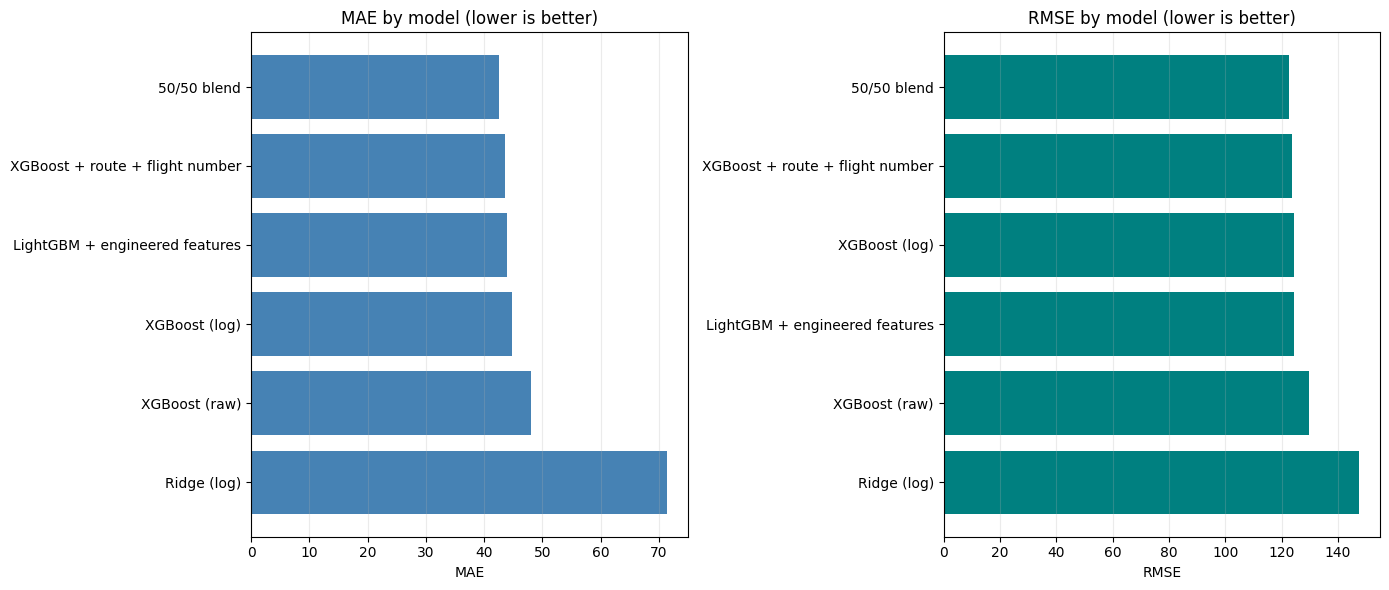

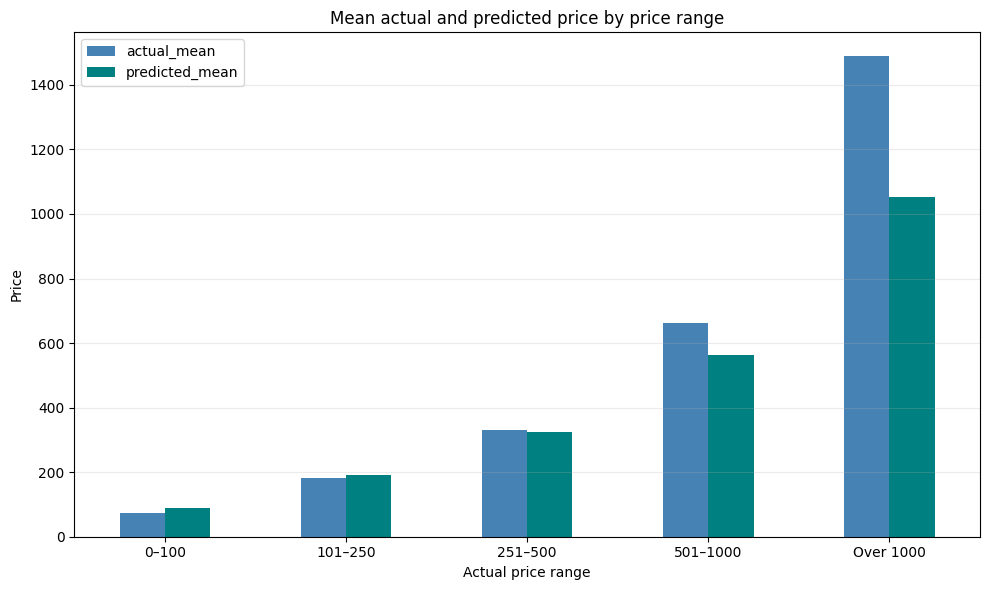

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Figure 1: model comparison
scores = pd.DataFrame({
    "Model": [
        "Ridge (log)",
        "XGBoost (raw)",
        "XGBoost (log)",
        "XGBoost + route + flight number",
        "LightGBM + engineered features",
        "50/50 blend",
    ],
    "MAE": [71.37, 48.01, 44.76, 43.66, 44.02, 42.59],
    "RMSE": [147.55, 129.57, 124.42, 123.54, 124.46, 122.53],
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, metric, color in zip(
    axes, ["MAE", "RMSE"], ["steelblue", "teal"]
):
    ordered = scores.sort_values(metric, ascending=True)
    ax.barh(ordered["Model"], ordered[metric], color=color)
    ax.set_title(f"{metric} by model (lower is better)")
    ax.set_xlabel(metric)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig("figure1_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2: average prediction versus actual price by fare range
# oof_predictions should come from the baseline log-target XGBoost OOF cell.
oof_plot = pd.DataFrame({
    "actual": np.asarray(y),
    "predicted": np.asarray(oof_predictions),
})

bins = [-1, 100, 250, 500, 1000, float("inf")]
labels = ["0–100", "101–250", "251–500", "501–1000", "Over 1000"]
oof_plot["price_range"] = pd.cut(
    oof_plot["actual"], bins=bins, labels=labels
)

band_summary = oof_plot.groupby("price_range", observed=False).agg(
    actual_mean=("actual", "mean"),
    predicted_mean=("predicted", "mean"),
)

band_summary.plot(kind="bar", figsize=(10, 6), color=["steelblue", "teal"])
plt.title("Mean actual and predicted price by price range")
plt.xlabel("Actual price range")
plt.ylabel("Price")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("figure2_price_band_errors.png", dpi=200, bbox_inches="tight")
plt.show()